In [101]:
from sympy import *
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.integrate import cumulative_trapezoid

In [102]:
#list of necessary parameters
parameters = {
    'm': 0.931,      #mass, kg
    'g': 9.81,   #acceleration due to gravity, m/s^2
    'Ct': 1.292e-5,    #Thrust coefficient
    'Cm': 1.197e-6,    #Moment coefficient
    'Ixx': 1.07e-2,    #Inertia in x, kg*m^2
    'Iyy': 1.01e-2,    #Inertia in y, kg*m^2
    'Izz': 1.90e-2,    #Inertia in z, kg*m^2
    'L': 0.225,        #Length of arm, m 
    'Vb': 11.1,        #Nominal Voltage, V
    'Cb': 3300,        #Battery Capacity, mAh
    'meff': 0.85,      #Motor efficiency, assumed
}

In [103]:
#Controller mixer matrix
def mix(T, taux, tauy, tauz, parameters):
   
    Ct = parameters['Ct']
    Cm = parameters['Cm']
    L = parameters['L']
    
#find torque to thrust ratio
    c = Cm / Ct

#perpendicular distance from center to motor
    d = L / np.sqrt(2)
    
#find the mixer matrix
    B = np.array([
        [1, 1, 1, 1],
        [-d, d, d, -d],
        [-d, -d, d, d],
        [c, -c, c, -c]
    ])
    
#define commanded thrust and torque
    Tcmd = np.array([T, taux, tauy, tauz]) #heave, roll, pitch, yaw
    
#define propeller thrust and torque
    Tprop = np.linalg.solve(B, Tcmd)
    Tprop = np.clip(Tprop, 0, None)
    
#convert propeller thrust to angular velocity
    omega = np.sqrt(Tprop / Ct)
    return omega


In [104]:
#Equations of motion
def eoms(t, u, parameters, controller):

#current state of the drone
    x, y, z, vx, vy, vz, phi, theta, psi, p, q, r = u

#find angular velocity of each motor
    omega = controller(t, u, parameters)
    omega1, omega2, omega3, omega4 = omega
    
    m = parameters['m']
    g = parameters['g']
    Ct = parameters['Ct']
    Cm = parameters['Cm']
    L = parameters['L']
    Ixx = parameters['Ixx']
    Iyy = parameters['Iyy']
    Izz = parameters['Izz']

#calculate motor thrusts and torques
    T1 = Ct * omega1**2
    T2 = Ct * omega2**2
    T3 = Ct * omega3**2
    T4 = Ct * omega4**2
    Ttot = T1 + T2 + T3 + T4
    
#roll, pitch, and yaw torques
    taux = d * (-T1 + T2 + T3 - T4)
    tauy = d * (-T1 - T2 + T3 + T4)
    tauz = (Cm / Ct) * (T1 - T2 + T3 - T4)

#linear accelerations
    ax = (Ttot/m) * (np.cos(psi)*np.sin(theta)*np.cos(phi) + np.sin(psi)*np.sin(phi))
    ay = (Ttot/m) * (np.sin(psi)*np.sin(theta)*np.cos(phi) - np.cos(psi)*np.sin(phi))
    az = (Ttot/m) * np.cos(theta)*np.cos(phi) - g

#angular accelerations
    p_dot = (taux + (Iyy - Izz)*q*r) / Ixx
    q_dot = (tauy + (Izz - Ixx)*p*r) / Iyy
    r_dot = (tauz + (Ixx - Iyy)*p*q) / Izz

#euler angle rates
    phi_dot = p + (q*np.sin(phi) + r*np.cos(phi))*np.tan(theta)
    theta_dot = q*np.cos(phi) - r*np.sin(phi)
    psi_dot = (q*np.sin(phi) + r*np.cos(phi))/np.cos(theta)

    return np.array([vx, vy, vz, ax, ay, az, phi_dot, theta_dot, psi_dot, p_dot, q_dot, r_dot])

In [105]:
#Controller
def control(t, u, parameters, ref_func):

#current state
    x, y, z, vx, vy, vz, phi, theta, psi, p, q, r = u

    m = parameters['m']
    g = parameters['g']
    Ixx = parameters['Ixx']
    Iyy = parameters['Iyy']
    Izz = parameters['Izz']

#desired positions and velocities
    xref, yref, zref, psiref, vxref, vyref, vzref = ref_func(t)

#position controller gains
    Kp_pos = 2.0
    Kd_pos = 2.0
    Kp_z = 5.0
    Kd_z = 4.0

#desired linear accelerations
    ax_des = Kp_pos*(xref - x) + Kd_pos*(vxref - vx)
    ay_des = Kp_pos*(yref - y) + Kd_pos*(vyref - vy)
    az_des = Kp_z*(zref - z) + Kd_z*(vzref - vz)

#total thrust command
    T = m*(g + az_des)/(np.cos(phi)*np.cos(theta))
    T = np.clip(T, 0, None)

#desired pitch and roll angles
    theta_des = (ax_des*np.cos(psi) + ay_des*np.sin(psi))/g
    phi_des = (ax_des*np.sin(psi) - ay_des*np.cos(psi))/g

#limit desired angles to 25 degrees
    max_angle = np.radians(25)
    theta_des = np.clip(theta_des, -max_angle, max_angle)
    phi_des = np.clip(phi_des, -max_angle, max_angle)

#attitude controller gains
    Kp_att = 10.0
    Kd_att = 5.0
    Kp_yaw = 5.0
    Kd_yaw = 2.0

#desired angular accelerations
    p_dot_des = Kp_att*(phi_des - phi) - Kd_att*p
    q_dot_des = Kp_att*(theta_des - theta) - Kd_att*q

#yaw control
    psi_error = (psiref - psi + np.pi) % (2*np.pi) - np.pi
    r_dot_des = Kp_yaw*psi_error - Kd_yaw*r

#required torques
    taux = Ixx*p_dot_des - (Iyy - Izz)*q*r
    tauy = Iyy*q_dot_des - (Izz - Ixx)*p*r
    tauz = Izz*r_dot_des - (Ixx - Iyy)*p*q

#convert thrust and torques to motor speeds
    return mix(T, taux, tauy, tauz, parameters)


In [106]:
#Energy use
def energy(sol, ref_func, parameters, goal):

    # Battery information
    V = parameters['Vb']
    C = parameters['Cb'] / 1000  # mAh to Ah
    eff = parameters['meff']
    Cm = parameters['Cm']

#total battery energy (Wh)
    E = V * C

#motor speeds throughout simulation
    omega = []

    for i in range(len(sol.t)):
        t = sol.t[i]
        u = sol.y[:, i]

        w = control(t, u, parameters, ref_func)
        omega.append(w)

    omega = np.array(omega)

#electrical power (W)
    power = Cm * np.sum(omega**3, axis=1) / eff

#cumulative energy consumption (Wh)
    energy = cumulative_trapezoid(power, sol.t, initial=0) / 3600

#plot
    plt.figure(figsize=(8, 5))

    plt.plot(sol.t, energy, label='Energy Consumed')
    plt.axhline(E, color='blue', linestyle='--', label='Battery Capacity')

    plt.xlabel('Time (s)')
    plt.ylabel('Energy (Wh)')
    plt.title(goal + ': Energy Consumption')
    plt.legend()
    plt.grid()
    plt.show()

    print('Available Battery Energy:', E, 'Wh')
    print('Estimated Energy Consumed:', energy[-1], 'Wh')
    print('Estimated Battery Used:', 100 * energy[-1] / E, '%')

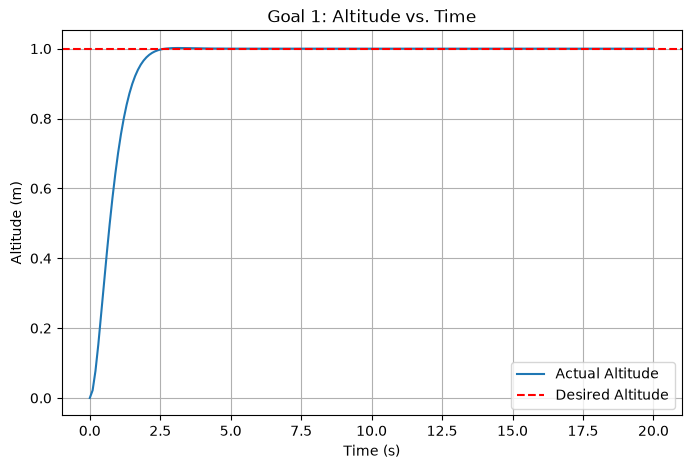

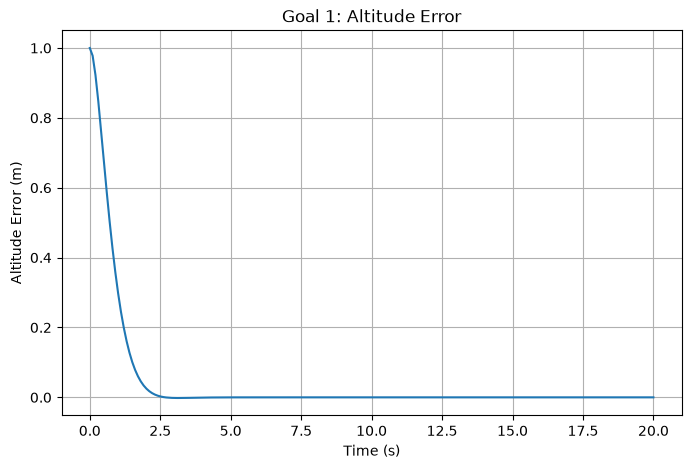

Maximum altitude error: 1.0 m
Final altitude error: 0.0 m


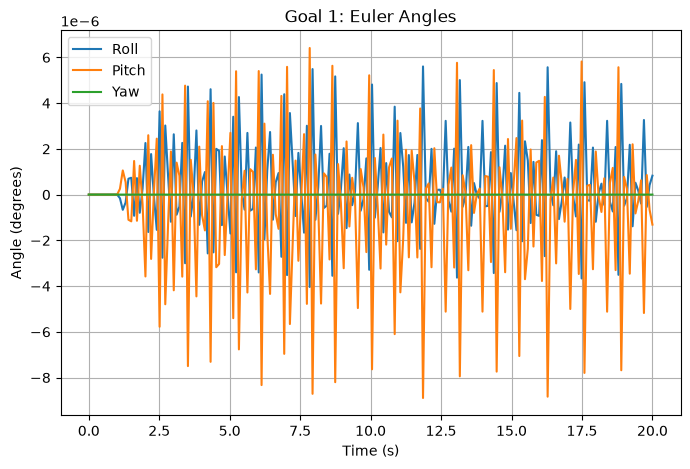

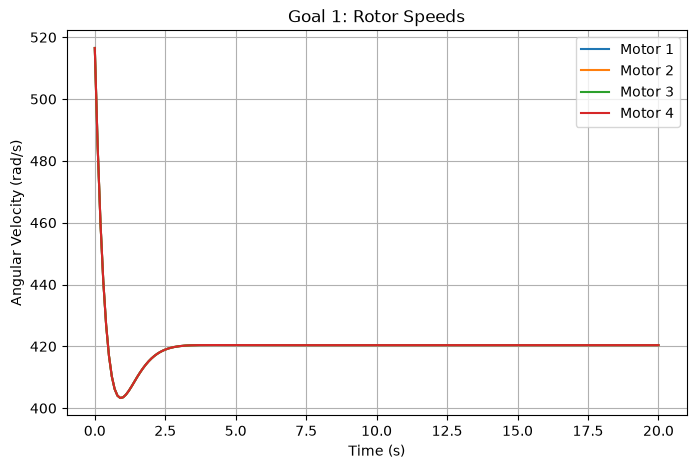

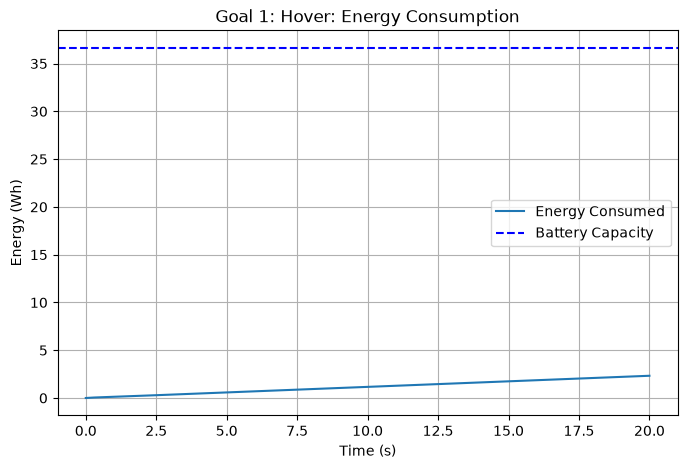

Available Battery Energy: 36.629999999999995 Wh
Estimated Energy Consumed: 2.3266406667275326 Wh
Estimated Battery Used: 6.351735371901537 %


In [107]:
#Hover at 1 m
def ref_hover(t):
    return 0, 0, 1, 0, 0, 0, 0

#initial conditions
u0 = np.zeros(12)

#simulation
sol = solve_ivp(
    lambda t, u: eoms(
        t, u, parameters,
        lambda t, u, p: control(t, u, p, ref_hover)
    ),
    (0, 20),
    u0,
    t_eval=np.linspace(0, 20, 200)
)

#plot

#altitude
plt.figure(figsize=(8, 5))

plt.plot(sol.t, sol.y[2], label='Actual Altitude')
plt.axhline(1, color='red', linestyle='--', label='Desired Altitude')

plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.title('Goal 1: Altitude vs. Time')
plt.legend()
plt.grid()
plt.show()

#altitude error
altitude_error = 1 - sol.y[2]

plt.figure(figsize=(8, 5))

plt.plot(sol.t, altitude_error)

plt.xlabel('Time (s)')
plt.ylabel('Altitude Error (m)')
plt.title('Goal 1: Altitude Error')
plt.grid()
plt.show()

print('Maximum altitude error:', np.max(np.abs(altitude_error)), 'm')
print('Final altitude error:', altitude_error[-1], 'm')

#euler angles
plt.figure(figsize=(8, 5))

plt.plot(sol.t, np.degrees(sol.y[6]), label='Roll')
plt.plot(sol.t, np.degrees(sol.y[7]), label='Pitch')
plt.plot(sol.t, np.degrees(sol.y[8]), label='Yaw')

plt.xlabel('Time (s)')
plt.ylabel('Angle (degrees)')
plt.title('Goal 1: Euler Angles')
plt.legend()
plt.grid()
plt.show()

#rotor speeds
omega_hover = []

for i in range(len(sol.t)):
    t = sol.t[i]
    u = sol.y[:, i]

    omega = control(t, u, parameters, ref_hover)
    omega_hover.append(omega)

omega_hover = np.array(omega_hover)

plt.figure(figsize=(8, 5))

plt.plot(sol.t, omega_hover[:, 0], label='Motor 1')
plt.plot(sol.t, omega_hover[:, 1], label='Motor 2')
plt.plot(sol.t, omega_hover[:, 2], label='Motor 3')
plt.plot(sol.t, omega_hover[:, 3], label='Motor 4')

plt.xlabel('Time (s)')
plt.ylabel('Angular Velocity (rad/s)')
plt.title('Goal 1: Rotor Speeds')
plt.legend()
plt.grid()
plt.show()

#energy use
energy(sol, ref_hover, parameters, 'Goal 1: Hover')

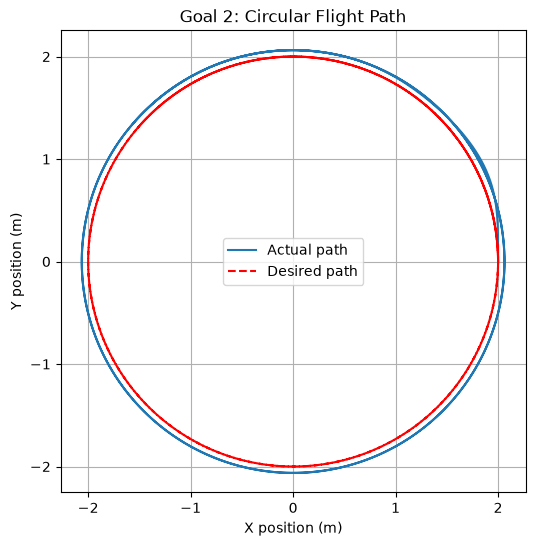

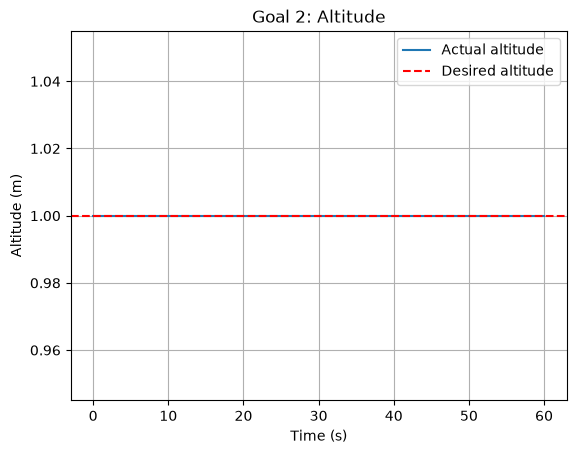

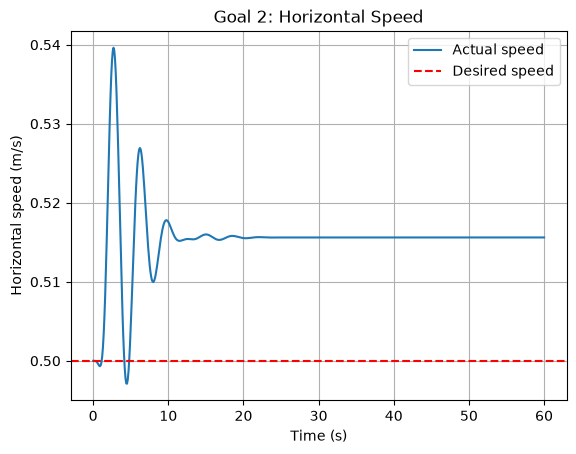

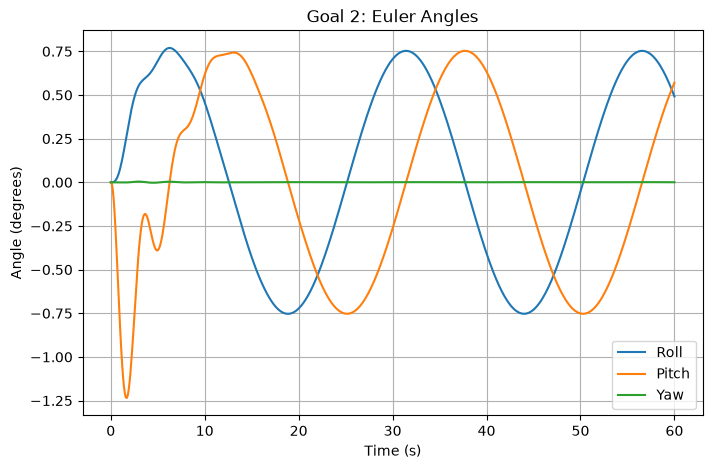

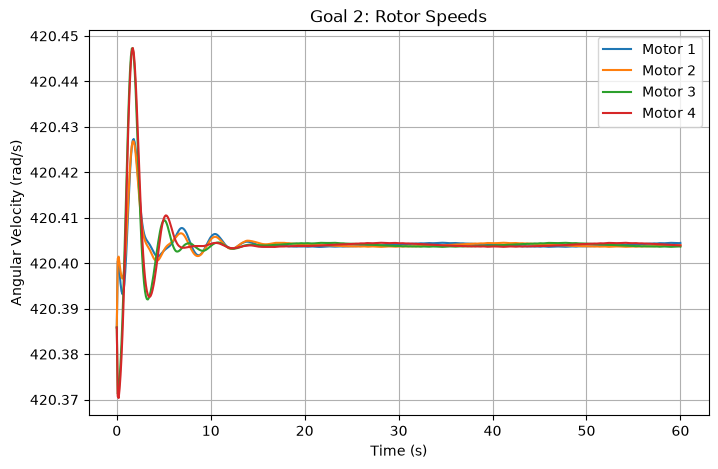

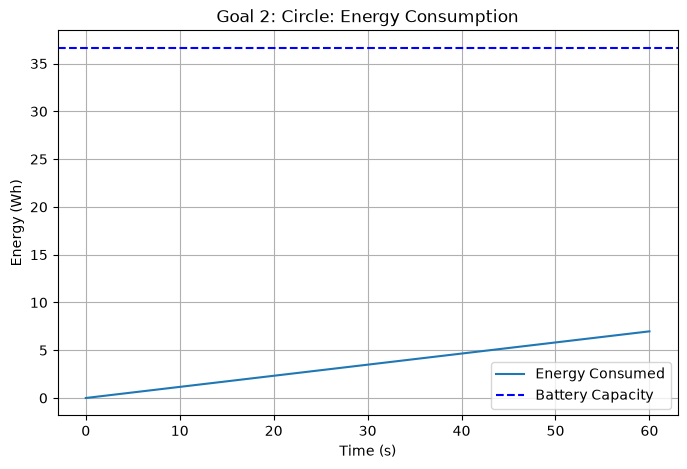

Available Battery Energy: 36.629999999999995 Wh
Estimated Energy Consumed: 6.975662518801177 Wh
Estimated Battery Used: 19.043577719904935 %


In [108]:
#Circle at 0.5m/s with a radius of 2m
def ref_circle(t):

    R = 2.0      #radius of circular path, m
    v = 0.5      #horizontal speed, m/s

    omega = v / R

#desired positions
    xref = R * np.cos(omega*t)
    yref = R * np.sin(omega*t)
    zref = 1.0                     #altitude, m

#desired yaw angle
    psiref = 0

#desired velocities
    vxref = -R*omega*np.sin(omega*t)
    vyref = R*omega*np.cos(omega*t)
    vzref = 0

    return xref, yref, zref, psiref, vxref, vyref, vzref

#initial conditions
u0_circle = np.zeros(12)

u0_circle[0] = 2.0    #initial x position, m
u0_circle[1] = 0.0    #initial y position, m
u0_circle[2] = 1.0    #initial altitude, m

u0_circle[3] = 0.0    #initial x velocity, m/s
u0_circle[4] = 0.5    #initial y velocity, m/s
u0_circle[5] = 0.0    #initial z velocity, m/s

#simulation
sol_circle = solve_ivp(
    lambda t, u: eoms(
        t, u, parameters,
        lambda t, u, p: control(t, u, p, ref_circle)
    ),
    (0, 60),
    u0_circle,
    t_eval=np.linspace(0, 60, 600),
    method='RK45'
)

#plot
t = np.linspace(0, 60, 600)

xref = 2*np.cos(0.25*t)
yref = 2*np.sin(0.25*t)

plt.figure(figsize=(6, 6))
plt.plot(sol_circle.y[0], sol_circle.y[1], label='Actual path')
plt.plot(xref, yref, 'r--', label='Desired path')

plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')
plt.title('Goal 2: Circular Flight Path')
plt.axis('equal')
plt.legend()
plt.grid()
plt.show()

plt.plot(sol_circle.t, sol_circle.y[2], label='Actual altitude')
plt.axhline(1.0, color='red', linestyle='--', label='Desired altitude')

plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.title('Goal 2: Altitude')
plt.legend()
plt.grid()
plt.show()

#calculate horizontal speed
vx = sol_circle.y[3]
vy = sol_circle.y[4]

v_horizontal = np.sqrt(vx**2 + vy**2)

#plot speed
plt.plot(sol_circle.t, v_horizontal, label='Actual speed')
plt.axhline(0.5, color='red', linestyle='--', label='Desired speed')

plt.xlabel('Time (s)')
plt.ylabel('Horizontal speed (m/s)')
plt.title('Goal 2: Horizontal Speed')
plt.legend()
plt.grid()
plt.show()

#euler angles
plt.figure(figsize=(8, 5))

plt.plot(sol_circle.t, np.degrees(sol_circle.y[6]), label='Roll')
plt.plot(sol_circle.t, np.degrees(sol_circle.y[7]), label='Pitch')
plt.plot(sol_circle.t, np.degrees(sol_circle.y[8]), label='Yaw')

plt.xlabel('Time (s)')
plt.ylabel('Angle (degrees)')
plt.title('Goal 2: Euler Angles')
plt.legend()
plt.grid()
plt.show()

#rotor speeds
omega_circle = []

for i in range(len(sol_circle.t)):
    t = sol_circle.t[i]
    u = sol_circle.y[:, i]

    omega = control(t, u, parameters, ref_circle)
    omega_circle.append(omega)

omega_circle = np.array(omega_circle)

plt.figure(figsize=(8, 5))

plt.plot(sol_circle.t, omega_circle[:, 0], label='Motor 1')
plt.plot(sol_circle.t, omega_circle[:, 1], label='Motor 2')
plt.plot(sol_circle.t, omega_circle[:, 2], label='Motor 3')
plt.plot(sol_circle.t, omega_circle[:, 3], label='Motor 4')

plt.xlabel('Time (s)')
plt.ylabel('Angular Velocity (rad/s)')
plt.title('Goal 2: Rotor Speeds')
plt.legend()
plt.grid()
plt.show()

#energy use
energy(sol_circle, ref_circle, parameters, 'Goal 2: Circle')

The solver successfully reached the end of the integration interval.


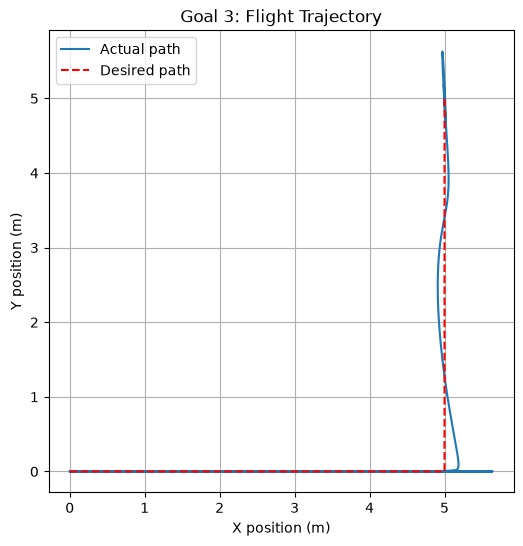

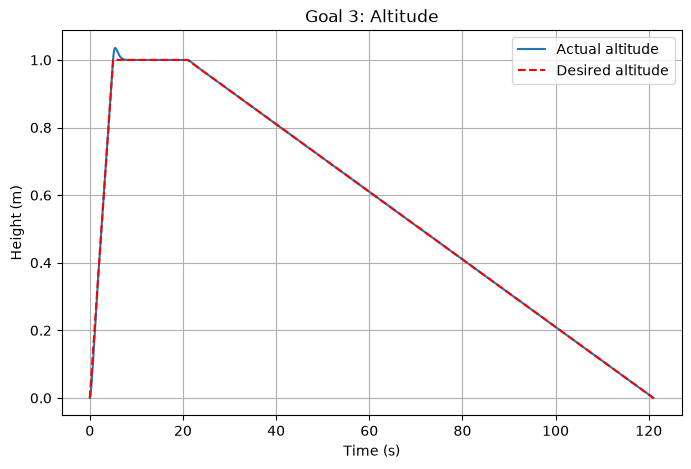

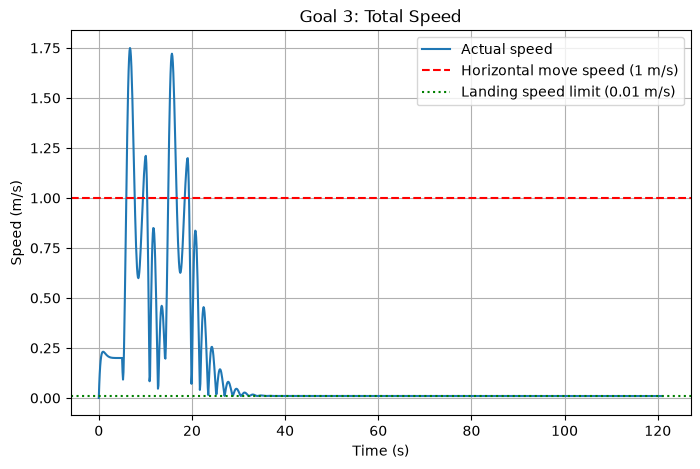

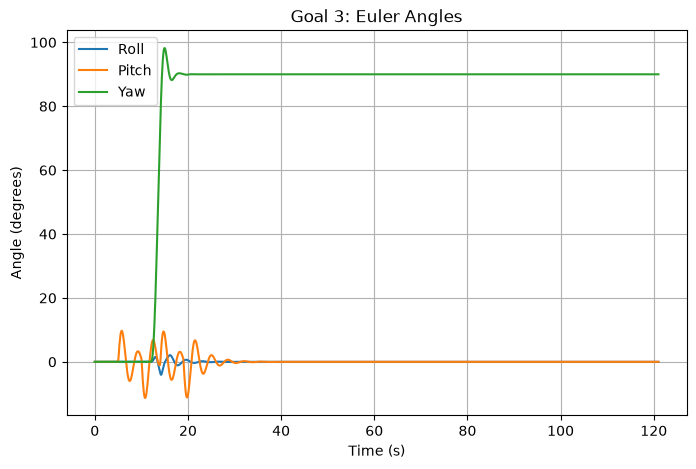

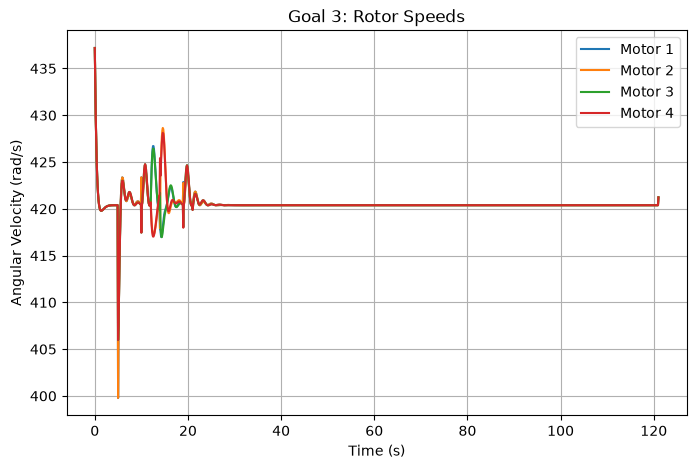

Drone did not reach the ground during the simulation.
Final altitude: 1.1085967213664283e-16 m


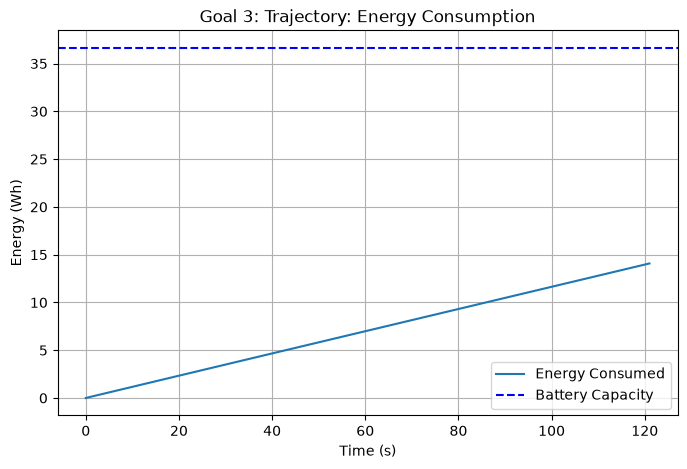

Available Battery Energy: 36.629999999999995 Wh
Estimated Energy Consumed: 14.079776865784657 Wh
Estimated Battery Used: 38.4378292814214 %


In [109]:
#Flight trajectory
def ref_traj(t):

#time of each maneuver, s
    t_ascend = 5
    t_move1 = 5
    t_wait1 = 2
    t_yaw = 2
    t_move2 = 5
    t_wait2 = 2
    t_land = 100

#end times of each maneuver
    T1 = t_ascend
    T2 = T1 + t_move1
    T3 = T2 + t_wait1
    T4 = T3 + t_yaw
    T5 = T4 + t_move2
    T6 = T5 + t_wait2
    T7 = T6 + t_land

#initially at the origin
    xref = 0
    yref = 0
    zref = 0
    psiref = 0

    vxref = 0
    vyref = 0
    vzref = 0

#ascend to 1 m
    if t < T1:
        zref = t / t_ascend
        vzref = 1 / t_ascend

#move forward 5 m in x
    elif t < T2:
        dt = t - T1
        xref = dt / t_move1 * 5
        zref = 1
        vxref = 5 / t_move1

#stop and hover
    elif t < T3:
        xref = 5
        zref = 1

#yaw 90 degrees left
    elif t < T4:
        dt = t - T3
        xref = 5
        zref = 1
        psiref = dt / t_yaw * (np.pi / 2)

#go forward 5 m in y
    elif t < T5:
        dt = t - T4
        xref = 5
        yref = dt / t_move2 * 5
        zref = 1
        psiref = np.pi / 2
        vyref = 5 / t_move2

#stop and hover
    elif t < T6:
        xref = 5
        yref = 5
        zref = 1
        psiref = np.pi / 2

#land vertically
    elif t < T7:
        dt = t - T6
        xref = 5
        yref = 5
        zref = 1 - dt / t_land
        psiref = np.pi / 2
        vzref = -1 / t_land

#final position
    else:
        xref = 5
        yref = 5
        zref = 0
        psiref = np.pi / 2

    return xref, yref, zref, psiref, vxref, vyref, vzref

#initial conditions
u0_traj = np.zeros(12)

#simulation
sol_traj = solve_ivp(
    lambda t, u: eoms(
        t, u, parameters,
        lambda t, u, p: control(t, u, p, ref_traj)
    ),
    (0, 121),
    u0_traj,
    t_eval=np.linspace(0, 121, 1211),
    method='RK45',
    max_step=0.1
)

print(sol_traj.message)

#desired path
xref = []
yref = []

for t in sol_traj.t:
    x, y, z, psi, vx, vy, vz = ref_traj(t)
    xref.append(x)
    yref.append(y)

#plot
plt.figure(figsize=(6, 6))

plt.plot(sol_traj.y[0], sol_traj.y[1], label='Actual path')
plt.plot(xref, yref, 'r--', label='Desired path')

plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')
plt.title('Goal 3: Flight Trajectory')
plt.axis('equal')
plt.legend()
plt.grid()
plt.show()

zref = []

for t in sol_traj.t:
    x, y, z, psi, vx, vy, vz = ref_traj(t)
    zref.append(z)

plt.figure(figsize=(8, 5))

plt.plot(sol_traj.t, sol_traj.y[2], label='Actual altitude')
plt.plot(sol_traj.t, zref, 'r--', label='Desired altitude')

plt.xlabel('Time (s)')
plt.ylabel('Height (m)')
plt.title('Goal 3: Altitude')
plt.legend()
plt.grid()
plt.show()

#calculate total speed
vx = sol_traj.y[3]
vy = sol_traj.y[4]
vz = sol_traj.y[5]

v_total = np.sqrt(vx**2 + vy**2 + vz**2)

plt.figure(figsize=(8, 5))

plt.plot(sol_traj.t, v_total, label='Actual speed')
plt.axhline(1.0, color='red', linestyle='--', label='Horizontal move speed (1 m/s)')
plt.axhline(0.01, color='green', linestyle=':', label='Landing speed limit (0.01 m/s)')

plt.xlabel('Time (s)')
plt.ylabel('Speed (m/s)')
plt.title('Goal 3: Total Speed')
plt.legend()
plt.grid()
plt.show()

#euler angles
plt.figure(figsize=(8, 5))

plt.plot(sol_traj.t, np.degrees(sol_traj.y[6]), label='Roll')
plt.plot(sol_traj.t, np.degrees(sol_traj.y[7]), label='Pitch')
plt.plot(sol_traj.t, np.degrees(sol_traj.y[8]), label='Yaw')

plt.xlabel('Time (s)')
plt.ylabel('Angle (degrees)')
plt.title('Goal 3: Euler Angles')
plt.legend()
plt.grid()
plt.show()

#rotor speeds
omega_traj = []

for i in range(len(sol_traj.t)):
    t = sol_traj.t[i]
    u = sol_traj.y[:, i]

    omega = control(t, u, parameters, ref_traj)
    omega_traj.append(omega)

omega_traj = np.array(omega_traj)

plt.figure(figsize=(8, 5))

plt.plot(sol_traj.t, omega_traj[:, 0], label='Motor 1')
plt.plot(sol_traj.t, omega_traj[:, 1], label='Motor 2')
plt.plot(sol_traj.t, omega_traj[:, 2], label='Motor 3')
plt.plot(sol_traj.t, omega_traj[:, 3], label='Motor 4')

plt.xlabel('Time (s)')
plt.ylabel('Angular Velocity (rad/s)')
plt.title('Goal 3: Rotor Speeds')
plt.legend()
plt.grid()
plt.show()

#find landing during final descent
landing_indices = np.where((sol_traj.t >= 21) & (sol_traj.y[2] <= 0))[0]

if len(landing_indices) > 0:
    i = landing_indices[0]

    print("Ground reached at:", sol_traj.t[i], "seconds")
    print("Vertical speed:", abs(sol_traj.y[5, i]), "m/s")
    print("Total speed:", v_total[i], "m/s")
else:
    print("Drone did not reach the ground during the simulation.")
    print("Final altitude:", sol_traj.y[2, -1], "m")

#energy use
energy(sol_traj, ref_traj, parameters, 'Goal 3: Trajectory')

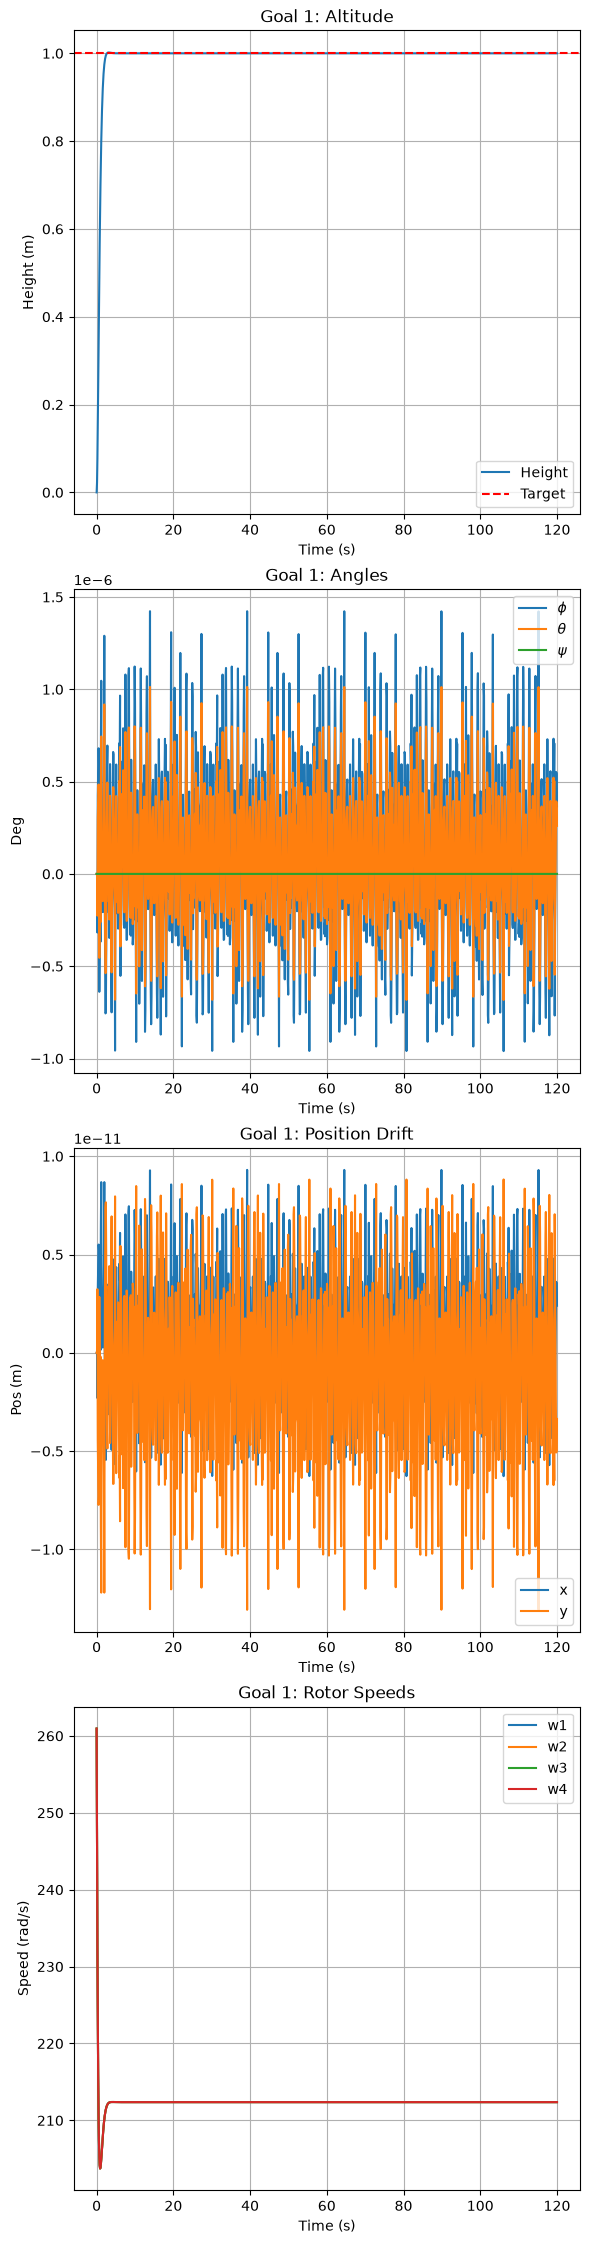

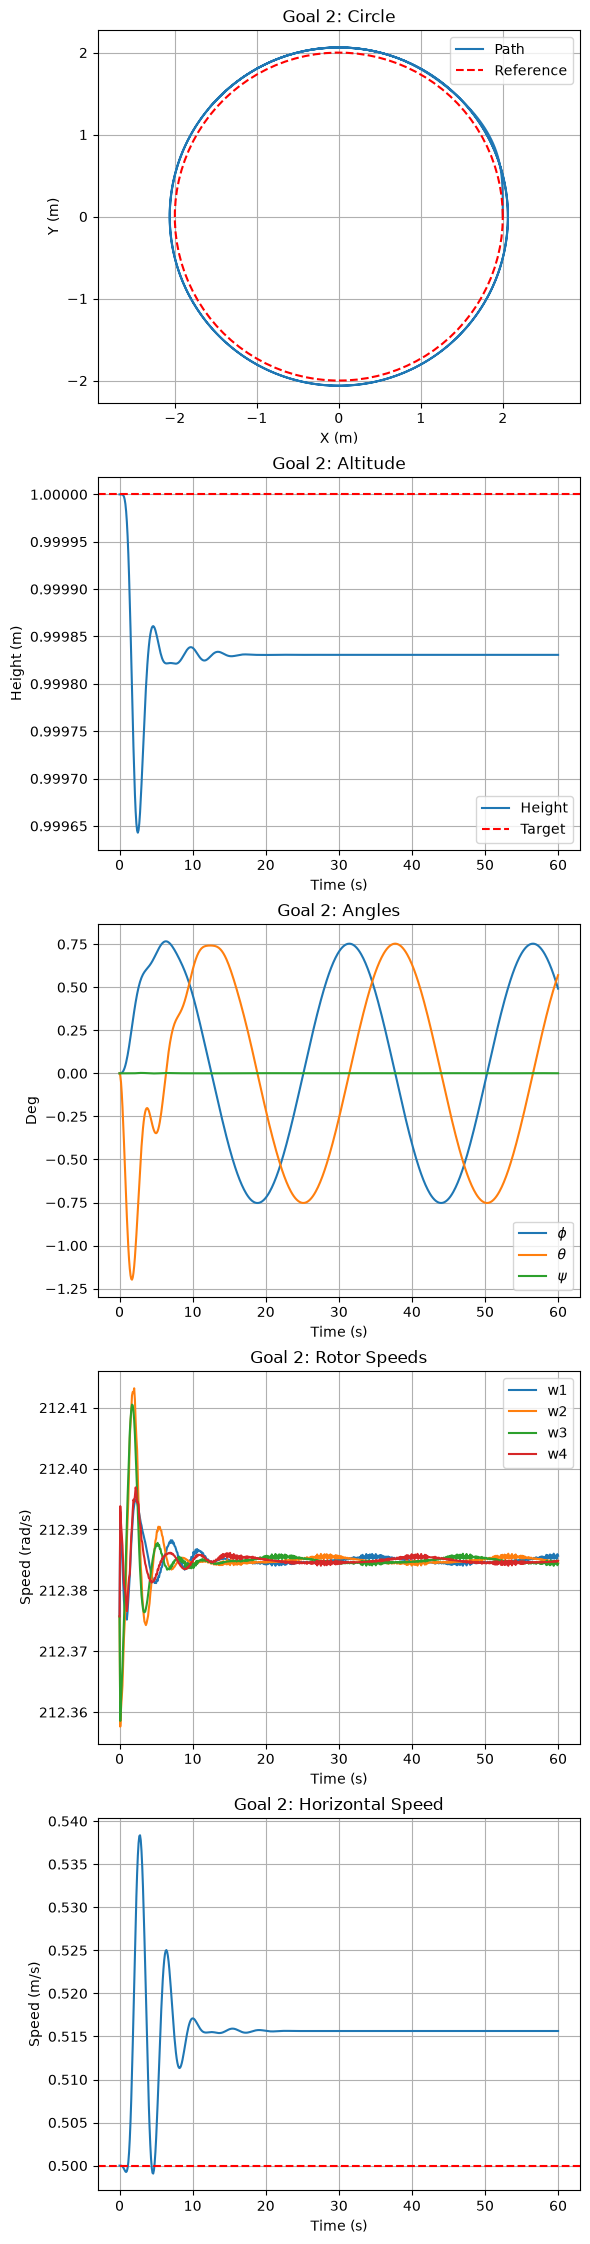

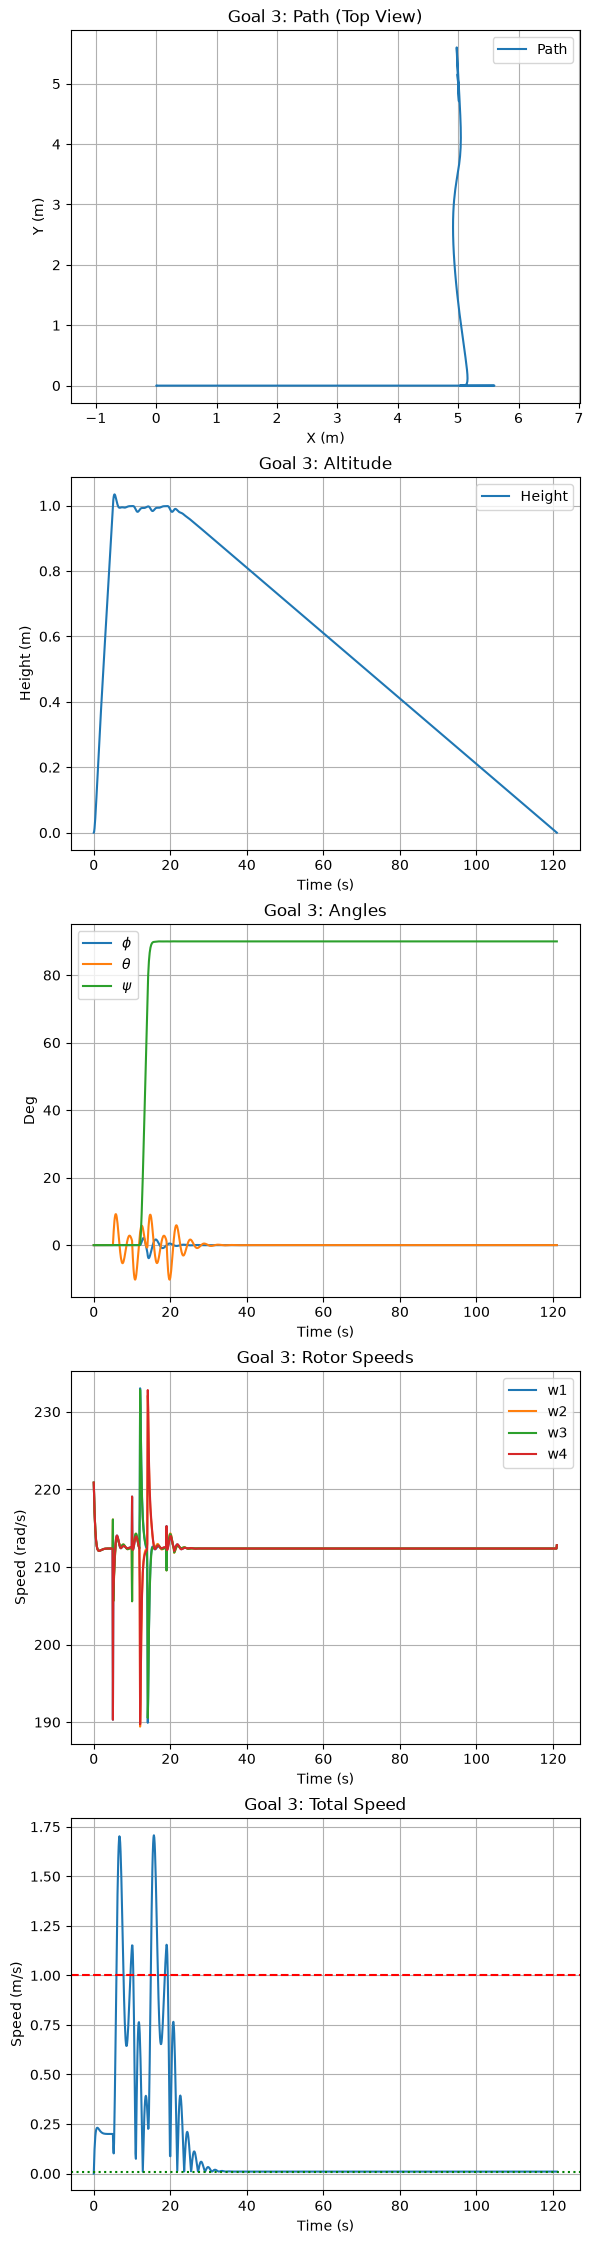

In [111]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

#not included angular velocities

params = { #updated to real
    "m":   3.2,        #mass (kg)
    "g":   9.81,       #gravity (m/s^2)
    "kf":  1.74e-4,    #thrust coeff
    "km":  4.17e-6,    #moment coeff
    "L":   0.325,      #arm length (m)
    "Ixx": 0.0361,     #inertia x (36.1 g m^2)
    "Iyy": 0.0361,     #inertia y (36.1 g m^2)
    "Izz": 0.0955      #inertia z (95.5 g m^2)
}

def mixer(FT, tau_x, tau_y, tau_z, params):
    kf, km, L = params["kf"], params["km"], params["L"]
    
    #inverse mix matrix
    M = np.array([
        [ kf, kf, kf, kf], #FT
        [-kf*L, -kf*L, kf*L,    kf*L], #tau_x roll
        [-kf*L, kf*L, kf*L, -kf*L], #tau_y pitch
        [ km, -km, km, -km]  #tau_z yaw
    ])
    
    rhs = np.array([FT, tau_x, tau_y, tau_z])
    w_sq = np.linalg.solve(M, rhs)
    w_sq = np.clip(w_sq, 0.0, None)
    return np.sqrt(w_sq)

#eqs of motion
def quad_eom(t, u, params, ctrl_func):
    #positions, velocities, euler angles, angular rates
    x, y, z, vx, vy, vz, phi, theta, psi, p, q, r = u
    
    #get control inputs (motor speeds)
    w = ctrl_func(t, u, params)
    w1, w2, w3, w4 = w
    
    #net forces + torques
    kf, km, L = params["kf"], params["km"], params["L"]
    FT = kf * np.sum(w**2)
    tau_x = kf * L * (w3**2 + w4**2 - w1**2 - w2**2)
    tau_y = kf * L * (w2**2 + w3**2 - w1**2 - w4**2)
    tau_z = km * (w1**2 + w3**2 - w2**2 - w4**2)
    
    #translational dynamics in inertial frame
    #uses R = Rz * Ry * Rx from doc
    m, g = params["m"], params["g"]
    
    ax = (FT / m) * (np.cos(psi)*np.sin(theta)*np.cos(phi) + np.sin(psi)*np.sin(phi))
    ay = (FT / m) * (np.sin(psi)*np.sin(theta)*np.cos(phi) - np.cos(psi)*np.sin(phi))
    az = (FT / m) * (np.cos(theta)*np.cos(phi)) - g

    #rotational dynamics (euler)
    Ixx, Iyy, Izz = params["Ixx"], params["Iyy"], params["Izz"]
    p_dot = (tau_x + (Iyy - Izz)*q*r) / Ixx
    q_dot = (tau_y + (Izz - Ixx)*p*r) / Iyy
    r_dot = (tau_z + (Ixx - Iyy)*p*q) / Izz

    #kinematics (body rates to euler rates)
    #stop singularity at +- 90 deg
    ct = np.cos(theta) if abs(np.cos(theta)) > 0.001 else 0.001
    tt = np.tan(theta)
    
    phi_dot   = p + (q*np.sin(phi) + r*np.cos(phi)) * tt
    theta_dot = q*np.cos(phi) - r*np.sin(phi)
    psi_dot   = (q*np.sin(phi) + r*np.cos(phi)) / ct

    return np.array([vx, vy, vz, ax, ay, az, phi_dot, theta_dot, psi_dot, p_dot, q_dot, r_dot])

#controller
def ctrl_tracking(t, u, params, ref_gen):
    x, y, z, vx, vy, vz, phi, theta, psi, p, q, r = u
    m, g = params["m"], params["g"]
    
    #references
    xref, yref, zref, psiref, vxref, vyref, vzref = ref_gen(t)
    
    #position control, outer loop to desired accelerations
    Kp_pos, Kd_pos = 2.0, 2.0
    Kp_z,   Kd_z   = 5.0, 4.0
    
    ax_des = Kp_pos*(xref - x) + Kd_pos*(vxref - vx)
    ay_des = Kp_pos*(yref - y) + Kd_pos*(vyref - vy)
    az_des = Kp_z  *(zref - z) + Kd_z  *(vzref - vz) + g
    
    #thrust calcs
    #req hover ~31.4N
    FT = m * az_des
    FT = np.clip(FT, 0, 102.0) #clamp thrust, 4*25.5N max thrust per motor
    
    #attitude control, inner loop to desired torques
    #invert linearized dynamics to get desired roll/pitch from ax/ay
    theta_des = (ax_des * np.cos(psi) + ay_des * np.sin(psi)) / g
    phi_des = (ax_des * np.sin(psi) - ay_des * np.cos(psi)) / g
    
    #clamp desired angles to keep dynamics valid
    theta_des = np.clip(theta_des, -0.5, 0.5)
    phi_des   = np.clip(phi_des,   -0.5, 0.5)
    
    Kp_att, Kd_att = 10.0, 5.0
    Kp_yaw, Kd_yaw = 5.0,  2.0
    
    tau_x = Kp_att * (phi_des - phi) - Kd_att * p
    tau_y = Kp_att * (theta_des - theta) - Kd_att * q
    tau_z = Kp_yaw * (psiref - psi) - Kd_yaw * r
    
    return mixer(FT, tau_x, tau_y, tau_z, params)

def ref_hover(t):
    #goal 1: hover at 1m
    return 0, 0, 1.0, 0, 0, 0, 0

def ref_circle(t):
    #goal 2: circle radius 2m, speed 0.5m/s
    w = 0.25
    r = 2.0
    return r*np.cos(w*t), r*np.sin(w*t), 1.0, 0, -r*w*np.sin(w*t), r*w*np.cos(w*t), 0

def ref_traj(t):
    #goal 3: launch, move 5m, stop, yaw 90, move 5m, stop, land
    t_ascend = 5; 
    t_move1 = 5; #5m 1m/s
    t_wait1 = 2; 
    t_yaw = 2; 
    t_move2 = 5; #5m 1m/s
    t_wait2 = 2; 
    #must land at max 1cm/s -> 100s
    t_land = 100 
    
    #timings
    T1 = t_ascend
    T2 = T1 + t_move1
    T3 = T2 + t_wait1
    T4 = T3 + t_yaw
    T5 = T4 + t_move2
    T6 = T5 + t_wait2
    T7 = T6 + t_land
    
    x, y, z, psi, vx, vy, vz = 0, 0, 0, 0, 0, 0, 0
    
    if t < T1: #ascend
        z = (t/T1)*1.0; vz = 1.0/T1
    elif t < T2: #move x
        dt = t - T1
        z = 1.0; x = (dt/t_move1)*5.0; vx = 5.0/t_move1 #vx = 1 m/s
    elif t < T3: #wait
        z, x = 1.0, 5.0
    elif t < T4: #yaw left
        z, x = 1.0, 5.0
        dt = t - T3
        psi = (dt/t_yaw)*(np.pi/2)
    elif t < T5: #move y (relative forward)
        z, x, psi = 1.0, 5.0, np.pi/2
        dt = t - T4
        y = (dt/t_move2)*5.0; vy = 5.0/t_move2 #vy = 1 m/s
    elif t < T6: #wait
        z, x, y, psi = 1.0, 5.0, 5.0, np.pi/2
    elif t < T7: #land
        x, y, psi = 5.0, 5.0, np.pi/2
        dt = t - T6
        z = 1.0 - (dt/t_land)*1.0; vz = -1.0/t_land #vz = -0.01 m/s
    else: #done
        x, y, z, psi = 5.0, 5.0, 0.0, np.pi/2
        
    return x, y, z, psi, vx, vy, vz

#sim driver
def run_sim(goal, T):
    ref = {'Hover': ref_hover, 'Circle': ref_circle, 'Traj': ref_traj}[goal]
    u0 = np.zeros(12)
    
    #for circle, start on the path
    if goal == 'Circle':
        x0, y0, z0, psi0, vx0, vy0, vz0 = ref(0)
        u0[0], u0[1], u0[2] = x0, y0, z0
        u0[3], u0[4] = vx0, vy0

    #solve ode
    sol = solve_ivp(
        #solve_ivp needs f(t, y) so wrap to take params + ctrl for eom
        #outer lambda takes time and state from solver
        #creates a controller that fits shape that eom function accepts
        lambda t, y: quad_eom(t, y, params, lambda t, u, p: ctrl_tracking(t, u, p, ref)),
        #time span
        (0, T), 
        #initial state vector
        u0, 
        #evaluation points output at 10 points/sec
        t_eval=np.linspace(0, T, int(T*10)),  method='RK45' #runge kutta
    )
    
    #fix rotor speeds for plotting
    #sol.t: time history, sol.y for plot
    w_hist = []
    for i in range(len(sol.t)):
        w = ctrl_tracking(sol.t[i], sol.y[:, i], params, ref)
        w_hist.append(w)
    w_hist = np.array(w_hist)
    
    return sol, w_hist

#run, set time
sol1, w1 = run_sim("Hover", 120) #2 min
sol2, w2 = run_sim("Circle", 60) #1 min
sol3, w3 = run_sim("Traj", 121)  # 121 sec total

#plotting setup and speed calculation
v_h_2 = np.sqrt(sol2.y[3]**2 + sol2.y[4]**2) #g2 speed horizontal
v_total_3 = np.sqrt(sol3.y[3]**2 + sol3.y[4]**2 + sol3.y[5]**2) #g3 speed


#1
fig1, axes1 = plt.subplots(4, 1, figsize=(6, 24))

axes1[0].plot(sol1.t, sol1.y[2], label='Height')
axes1[0].axhline(1.0, color='r', linestyle='--', label='Target')
axes1[0].set_title("Goal 1: Altitude")
axes1[0].set_ylabel("Height (m)")
axes1[0].set_xlabel("Time (s)") 
axes1[0].legend()
axes1[0].grid(True)

axes1[1].plot(sol1.t, np.degrees(sol1.y[6:9].T))
axes1[1].set_title("Goal 1: Angles")
axes1[1].set_ylabel("Deg")
axes1[1].set_xlabel("Time (s)") 
axes1[1].legend(['$\phi$', r'$\theta$', '$\psi$'])
axes1[1].grid(True)

axes1[2].plot(sol1.t, sol1.y[0], label='x')
axes1[2].plot(sol1.t, sol1.y[1], label='y')
axes1[2].set_title("Goal 1: Position Drift")
axes1[2].set_ylabel("Pos (m)")
axes1[2].set_xlabel("Time (s)") 
axes1[2].legend()
axes1[2].grid(True)

axes1[3].plot(sol1.t, w1)
axes1[3].set_title("Goal 1: Rotor Speeds")
axes1[3].set_ylabel("Speed (rad/s)")
axes1[3].set_xlabel("Time (s)") 
axes1[3].legend(['w1', 'w2', 'w3', 'w4'])
axes1[3].grid(True)


plt.tight_layout()
plt.subplots_adjust(top=0.95, bottom=0.05)
#plt.savefig('C:/Users/cianm/OneDrive/Documents/AE 352/plots/goal1_hover.png')


#2
fig2, axes2 = plt.subplots(5, 1, figsize=(6, 24))

axes2[0].plot(sol2.y[0], sol2.y[1], label='Path')
theta = np.linspace(0, 2*np.pi, 100)
axes2[0].plot(2*np.cos(theta), 2*np.sin(theta), 'r--', label='Reference')
axes2[0].set_title("Goal 2: Circle")
axes2[0].set_ylabel("Y (m)")
axes2[0].set_xlabel("X (m)") 
axes2[0].axis('equal')
axes2[0].legend()
axes2[0].grid(True)

axes2[1].plot(sol2.t, sol2.y[2], label='Height')
axes2[1].axhline(1.0, color='r', linestyle='--', label='Target')
axes2[1].set_title("Goal 2: Altitude")
axes2[1].set_ylabel("Height (m)")
axes2[1].set_xlabel("Time (s)") 
axes2[1].legend()
axes2[1].grid(True)

axes2[2].plot(sol2.t, np.degrees(sol2.y[6:9].T))
axes2[2].set_title("Goal 2: Angles")
axes2[2].set_ylabel("Deg")
axes2[2].set_xlabel("Time (s)") 
axes2[2].legend(['$\phi$', r'$\theta$', '$\psi$']) 
axes2[2].grid(True)

axes2[3].plot(sol2.t, w2)
axes2[3].set_title("Goal 2: Rotor Speeds")
axes2[3].set_ylabel("Speed (rad/s)")
axes2[3].set_xlabel("Time (s)") 
axes2[3].legend(['w1', 'w2', 'w3', 'w4'])
axes2[3].grid(True)

axes2[4].plot(sol2.t, v_h_2, label='Horizontal Speed')
axes2[4].axhline(0.5, color='r', linestyle='--', label='Target (0.5 m/s)')
axes2[4].set_title("Goal 2: Horizontal Speed")
axes2[4].set_ylabel("Speed (m/s)")
axes2[4].set_xlabel("Time (s)") 
axes2[4].grid(True)

plt.tight_layout()
plt.subplots_adjust(top=0.95, bottom=0.05)
#plt.savefig('C:/Users/cianm/OneDrive/Documents/AE 352/plots/goal2_circle.png')


#3
fig3, axes3 = plt.subplots(5, 1, figsize=(6, 24))


axes3[0].plot(sol3.y[0], sol3.y[1], label='Path')
axes3[0].set_title("Goal 3: Path (Top View)")
axes3[0].set_ylabel("Y (m)")
axes3[0].set_xlabel("X (m)") 
axes3[0].axis('equal')
axes3[0].legend()
axes3[0].grid(True)

axes3[1].plot(sol3.t, sol3.y[2], label='Height')
axes3[1].set_title("Goal 3: Altitude")
axes3[1].set_ylabel("Height (m)")
axes3[1].set_xlabel("Time (s)") 
axes3[1].legend()
axes3[1].grid(True)

axes3[2].plot(sol3.t, np.degrees(sol3.y[6:9].T))
axes3[2].set_title("Goal 3: Angles")
axes3[2].set_ylabel("Deg")
axes3[2].set_xlabel("Time (s)") 
axes3[2].legend(['$\phi$', r'$\theta$', '$\psi$'])
axes3[2].grid(True)

axes3[3].plot(sol3.t, w3)
axes3[3].set_title("Goal 3: Rotor Speeds")
axes3[3].set_ylabel("Speed (rad/s)")
axes3[3].set_xlabel("Time (s)") 
axes3[3].legend(['w1', 'w2', 'w3', 'w4'])
axes3[3].grid(True)

axes3[4].plot(sol3.t, v_total_3, label='Total Speed')
axes3[4].axhline(1.0, color='r', linestyle='--', label='Target Move Speed (1m/s)')
axes3[4].axhline(0.01, color='g', linestyle=':', label='Target Land Speed (0.01m/s)')
axes3[4].set_title("Goal 3: Total Speed")
axes3[4].set_ylabel("Speed (m/s)")
axes3[4].set_xlabel("Time (s)") 
axes3[4].grid(True)

plt.tight_layout()
plt.subplots_adjust(top=0.95, bottom=0.05)
#plt.savefig('C:/Users/cianm/OneDrive/Documents/AE 352/plots/goal3_traj.png')
plt.show()